# Market analysis and stock segmentation 2021 to 2024

Unexecuted on real data. Run in order; download the outputs ZIP at the end. This notebook uses the brief’s volume-based RFM definitions. No synthetic fallback is provided. Check README and the original brief before preparing the final report.

In [1]:
%pip -q install "pandas>=2.2,<4" "numpy>=1.26,<3" "scipy>=1.12,<2" "scikit-learn>=1.4,<2" "matplotlib>=3.8,<4" "yfinance>=0.2.65,<1" "lxml>=5,<7" "html5lib>=1.1,<2" "beautifulsoup4>=4.12,<5"

## Implementation

All functions are embedded below. Running this cell defines the workflow; it does not download data yet.

In [2]:
"""6BUIS017W stock segmentation. Real data only; no fabricated fallback."""
from pathlib import Path
from datetime import datetime, timezone
from io import StringIO
import argparse
import hashlib
import importlib.metadata
import json
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

START, END, SEED = '2021-01-01', '2025-01-01', 42
FEATURES = ['MeanWeeklyReturn', 'WeeklyBeta', 'Recency', 'Frequency', 'Monetary']
VERSION = '1.0.0'


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=str))


def acquire(root, offline=False):
    """Save separate ticker histories so interrupted downloads can be resumed."""
    raw = root / 'data'
    raw.mkdir(parents=True, exist_ok=True)
    universe_path = raw / 'constituents.csv'
    manifest_path = raw / 'provenance.json'
    if not universe_path.exists():
        if offline:
            raise RuntimeError('Cached constituents.csv is required in offline mode.')
        url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
        request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(request, timeout=45) as response:
            html = response.read().decode('utf-8')
        (raw / 'constituents_source.html').write_text(html)
        universe = next(t for t in pd.read_html(StringIO(html)) if 'Symbol' in t.columns)
        universe['YahooTicker'] = universe['Symbol'].str.replace('.', '-', regex=False)
        universe.to_csv(universe_path, index=False)
        write_json(manifest_path, {'universe_source': url,
                   'universe_retrieved_utc': datetime.now(timezone.utc).isoformat(),
                   'start_inclusive': START, 'end_exclusive': END,
                   'price_source': 'Yahoo Finance via yfinance',
                   'adjustment_policy': 'auto_adjust=False; split-adjusted Close and compatible Volume; Adj Close for returns',
                   'histories': {}})
    if not manifest_path.exists():
        raise RuntimeError('Cached data require provenance.json; do not invent retrieval dates.')
    manifest = json.loads(manifest_path.read_text())
    if (manifest.get('start_inclusive'), manifest.get('end_exclusive')) != (START, END):
        raise RuntimeError('Cache period does not match the required study period.')
    universe = pd.read_csv(universe_path)
    tickers = ['^GSPC'] + universe['YahooTicker'].tolist()
    failures = []
    for number, ticker in enumerate(tickers, 1):
        path = raw / (ticker + '.csv')
        if path.exists():
            if ticker not in manifest['histories']:
                raise RuntimeError(f'No provenance for cached {ticker}')
            expected = manifest['histories'][ticker].get('sha256')
            if expected and hashlib.sha256(path.read_bytes()).hexdigest() != expected:
                raise RuntimeError(f'Cache checksum mismatch for {ticker}')
            continue
        if offline:
            failures.append({'Share': ticker, 'Reason': 'No cached history'})
            continue
        import yfinance as yf
        for attempt in range(3):
            try:
                d = yf.Ticker(ticker).history(start=START, end=END,
                        auto_adjust=False, actions=True, repair=False, raise_errors=True)
                if d.empty:
                    raise ValueError('Empty history')
                d.index = pd.to_datetime(d.index).tz_localize(None).normalize()
                d.index.name = 'Date'
                d.to_csv(path)
                manifest['histories'][ticker] = {
                    'retrieved_utc': datetime.now(timezone.utc).isoformat(),
                    'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
                write_json(manifest_path, manifest)
                print(f'{number}/{len(tickers)} {ticker}: saved', flush=True)
                break
            except Exception as error:
                if attempt == 2:
                    failures.append({'Share': ticker, 'Reason': str(error)})
                else:
                    time.sleep(2 ** attempt)
        time.sleep(0.25)
    pd.DataFrame(failures, columns=['Share', 'Reason']).to_csv(raw / 'download_failures.csv', index=False)
    return universe


def read_history(path):
    d = pd.read_csv(path, parse_dates=['Date']).set_index('Date').sort_index()
    return d.loc[(d.index >= START) & (d.index < END)]


def weekly_prices(prices):
    """Keep full calendar weeks only, including ordinary holiday-shortened weeks."""
    w = prices.resample('W-FRI').last()
    monday = w.index - pd.Timedelta(days=4)
    return w.loc[(monday >= pd.Timestamp(START)) & (w.index < pd.Timestamp(END))]


def activity(d, observation):
    baseline = d['Volume'].shift(1).rolling(20, min_periods=20).mean()
    events = baseline.notna() & (d['Volume'] > 2 * baseline)
    dates = d.index[events]
    recency = (observation - dates[-1]).days if len(dates) else np.nan
    recent = d.tail(60)
    assert len(recent) == 60 and baseline.loc[recent.index].notna().all()
    detail = pd.DataFrame({'Close': d['Close'], 'Volume': d['Volume'],
                           'Previous20Mean': baseline, 'Threshold': 2 * baseline,
                           'HighVolume': events, 'DailyTradedValue': d['Close'] * d['Volume']})
    return recency, int(events.loc[recent.index].sum()), float(detail.loc[recent.index, 'DailyTradedValue'].sum()), detail


def prepare(root, universe):
    out = root / 'outputs'
    out.mkdir(exist_ok=True)
    benchmark = read_history(root / 'data' / '^GSPC.csv')
    if benchmark.index.duplicated().any():
        raise ValueError('Duplicate benchmark dates')
    if benchmark.empty or benchmark.index.min() > pd.Timestamp('2021-01-04') or benchmark.index.max() < pd.Timestamp('2024-12-31'):
        raise ValueError('Benchmark lacks required period endpoints')
    for col in ['Close', 'Adj Close']:
        if col not in benchmark or benchmark[col].isna().any() or (benchmark[col] <= 0).any():
            raise ValueError('Invalid benchmark ' + col)
    sessions = benchmark.index
    observation = sessions[-1]
    market = weekly_prices(benchmark['Adj Close']).pct_change(fill_method=None)
    rows, log, corporate = [], [], []
    for _, share in universe.iterrows():
        ticker = share['YahooTicker']
        try:
            d = read_history(root / 'data' / (ticker + '.csv'))
            if d.index.duplicated().any():
                raise ValueError('Duplicate dates')
            if not d.index.equals(sessions):
                raise ValueError('Unequal or missing daily history; strict full-period coverage rule')
            for col in ['Close', 'Adj Close', 'Volume']:
                if col not in d or not np.isfinite(d[col]).all():
                    raise ValueError('Missing or nonfinite ' + col)
            if (d[['Close', 'Adj Close']] <= 0).any().any():
                raise ValueError('Nonpositive price')
            if (d['Volume'] < 0).any() or (d['Volume'] % 1 != 0).any():
                raise ValueError('Negative or fractional volume')
            if (d['Volume'] == 0).any():
                raise ValueError('Zero volume on benchmark trading session')
            splits = d.get('Stock Splits', pd.Series(0., index=d.index)).fillna(0)
            dividends = d.get('Dividends', pd.Series(0., index=d.index)).fillna(0)
            for date in d.index[(splits != 0) | (dividends != 0)]:
                corporate.append({'Share': ticker, 'Date': date, 'Split': splits.loc[date],
                                  'Dividend': dividends.loc[date], 'Close': d.loc[date, 'Close'],
                                  'AdjClose': d.loc[date, 'Adj Close']})
            # Yahoo Close already accounts for splits: applying split ratios again is incorrect.
            # Large close jumps near split dates are flagged for review, not automatically repaired.
            jumps = d['Close'].pct_change(fill_method=None).abs()
            split_near = (splits != 0).rolling(3, center=True, min_periods=1).max().astype(bool)
            if (split_near & (jumps > .8)).any():
                raise ValueError('Extreme close jump near split; manual adjustment review required')
            returns = weekly_prices(d['Adj Close']).pct_change(fill_method=None)
            pair = pd.concat([returns.rename('Share'), market.rename('Market')], axis=1).dropna()
            if len(pair) != market.notna().sum() or len(pair) < 100 or pair['Market'].var() <= 0:
                raise ValueError('Insufficient or misaligned weekly returns')
            beta = pair['Share'].cov(pair['Market']) / pair['Market'].var()
            r, f, m, detail = activity(d, observation)
            risk_ok = np.isfinite([returns.mean(), beta]).all()
            rows.append({'Share': ticker, 'Security': share['Security'],
                'Sector': share['GICS Sector'], 'MeanWeeklyReturn': pair['Share'].mean(),
                'WeeklyBeta': beta, 'PairedWeeks': len(pair), 'Recency': r,
                'Frequency': f, 'Monetary': m, 'ObservationDate': observation.date()})
            log.append({'Share': ticker, 'RiskIncluded': bool(risk_ok), 'RFMIncluded': pd.notna(r),
                        'Reason': 'Valid' if pd.notna(r) else 'No qualifying event in valid study history'})
            if not (out / 'worked_example_daily.csv').exists() and pd.notna(r):
                detail.to_csv(out / 'worked_example_daily.csv')
                detail.tail(60).to_csv(out / 'worked_example_60_sessions.csv')
                dates = detail.index[detail['HighVolume']]
                write_json(out / 'worked_example.json', {'Share': ticker,
                    'ObservationDate': observation.date(), 'LatestEventDate': dates[-1].date(),
                    'Recency': r, 'Frequency': f, 'Monetary': m,
                    'WindowStart': detail.tail(60).index[0].date()})
        except (ValueError, KeyError, FileNotFoundError) as error:
            log.append({'Share': ticker, 'RiskIncluded': False, 'RFMIncluded': False, 'Reason': str(error)})
    pd.DataFrame(log).to_csv(out / 'inclusion_exclusion_log.csv', index=False)
    pd.DataFrame(corporate).to_csv(out / 'corporate_actions.csv', index=False)
    features = pd.DataFrame(rows)
    if features.empty:
        raise RuntimeError('No valid shares; inspect validation and download logs.')
    features.to_csv(out / 'features_before_common_filter.csv', index=False)
    features = features.dropna(subset=FEATURES).set_index('Share').sort_index()
    if len(features) < 10:
        raise RuntimeError('Fewer than ten common valid shares; resolve data coverage before modelling.')
    features.to_csv(out / 'features.csv')
    features[FEATURES].describe().to_csv(out / 'feature_summary.csv')
    return features


def plot_save(out, name):
    plt.tight_layout()
    plt.savefig(out / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.close()


def cluster(root, features, overrides=None):
    out = root / 'outputs'
    overrides = overrides or {}
    xrfm = features[['Recency', 'Frequency', 'Monetary']].copy()
    xrfm['LogMonetary'] = np.log1p(xrfm.pop('Monetary'))
    xrfm.corr().to_csv(out / 'rfm_pearson_correlations.csv')
    xrfm.corr(method='spearman').to_csv(out / 'rfm_spearman_correlations.csv')
    matrices = {'RiskReturn': features[['MeanWeeklyReturn', 'WeeklyBeta']], 'RFM': xrfm}
    labels, diagnostics, choices, projections = {}, [], {}, {}
    for name, x in matrices.items():
        scaler = StandardScaler()
        z = scaler.fit_transform(x)
        if np.unique(z, axis=0).shape[0] < 9:
            raise ValueError('Too few distinct observations for k=2 to 8')
        pd.DataFrame(z, index=x.index, columns=x.columns).to_csv(out / (name + '_standardised.csv'))
        pd.DataFrame({'Mean': scaler.mean_, 'Scale': scaler.scale_}, index=x.columns).to_csv(out / (name + '_scaler.csv'))
        diagnostic = pd.DataFrame({'Skew': x.skew(), 'Minimum': x.min(), 'Maximum': x.max(),
            'AbsZAbove3': (np.abs(z) > 3).sum(axis=0)}, index=x.columns)
        diagnostic.to_csv(out / (name + '_skew_outliers.csv'))
        x.hist(bins=30, figsize=(10, 4))
        plot_save(out, name + '_feature_distributions')
        tree = linkage(z, method='ward', metric='euclidean')
        plt.figure(figsize=(16, 6))
        dendrogram(tree, labels=x.index.tolist(), leaf_font_size=3, leaf_rotation=90)
        plt.title(name + ' Ward dendrogram')
        plt.xlabel('Share ticker'); plt.ylabel('Ward linkage distance')
        plot_save(out, name + '_dendrogram')
        if name == 'RFM':
            pca = PCA(n_components=2)
            projection = pca.fit_transform(z)
            projections[name] = {'explained_variance_ratio': pca.explained_variance_ratio_.tolist(),
                'loadings': pca.components_.tolist(), 'features': x.columns.tolist()}
            axislabels = [f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', f'PC2 ({pca.explained_variance_ratio_[1]:.1%})']
        else:
            projection = x.to_numpy(); axislabels = ['Arithmetic mean weekly return (decimal)', 'Weekly beta']
        for algorithm in ['Ward', 'KMeans']:
            candidates, candidates_labels = [], {}
            for k in range(2, 9):
                if algorithm == 'Ward':
                    lab = cut_tree(tree, n_clusters=k).ravel()
                    inertia = float(sum(((z[lab == j] - z[lab == j].mean(axis=0)) ** 2).sum() for j in np.unique(lab)))
                else:
                    model = KMeans(n_clusters=k, random_state=SEED, n_init=30)
                    lab = model.fit_predict(z); inertia = float(model.inertia_)
                sizes = np.bincount(lab)
                record = {'Matrix': name, 'Algorithm': algorithm, 'k': k,
                          'Silhouette': silhouette_score(z, lab), 'Inertia': inertia,
                          'MinSize': int(sizes.min()), 'Sizes': json.dumps(sizes.tolist())}
                candidates.append(record); diagnostics.append(record); candidates_labels[k] = lab
                features.assign(Cluster=lab + 1).groupby('Cluster')[FEATURES].mean().to_csv(out / f'{name}_{algorithm}_k{k}_candidate_profiles.csv')
            # Explicit provisional policy. Review candidate profiles before final interpretation.
            acceptable = [r for r in candidates if r['MinSize'] >= max(2, int(np.ceil(.02 * len(x))))]
            best = max(acceptable or candidates, key=lambda r: (r['Silhouette'], -r['k']))
            key = name + '_' + algorithm
            k = int(overrides.get(key, best['k']))
            if k not in candidates_labels:
                raise ValueError('Selected k must be between 2 and 8')
            lab = candidates_labels[k] + 1
            labels[key] = lab
            choices[key] = {'k': k, 'automatic_recommendation': best['k'],
                            'policy': 'Maximum silhouette among k with each cluster at least 2 percent of common shares (minimum 2); fallback all k. Review sizes, dendrograms and profiles.',
                            'human_override': key in overrides}
            profile = features.assign(Cluster=lab).groupby('Cluster')[FEATURES].agg(['count', 'mean', 'median'])
            profile.to_csv(out / (key + '_profiles.csv'))
            sectors = pd.crosstab(pd.Series(lab, index=features.index, name='Cluster'), features['Sector'])
            sectors.to_csv(out / (key + '_sector_counts.csv'))
            sectors.div(sectors.sum(axis=1), axis=0).to_csv(out / (key + '_sector_proportions.csv'))
            sectors.div(sectors.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(11, 5), colormap='tab20')
            plt.ylabel('Within-cluster sector proportion'); plt.title(key + ' sector composition')
            plt.legend(bbox_to_anchor=(1.02, 1), fontsize=7)
            plot_save(out, key + '_sectors')
            plt.figure(figsize=(10, 6))
            for j in np.unique(lab):
                mask = lab == j
                plt.scatter(projection[mask, 0], projection[mask, 1], label=f'Cluster {j} (n={mask.sum()})', s=18, alpha=.7)
            # Tickers for extreme points; complete labelled coordinates remain in the CSV.
            extreme = np.argsort(np.linalg.norm(z, axis=1))[-12:]
            for i in extreme:
                plt.annotate(x.index[i], projection[i], fontsize=7)
            plt.xlabel(axislabels[0]); plt.ylabel(axislabels[1]); plt.title(key); plt.legend()
            plot_save(out, key + '_scatter')
            pd.DataFrame({'Share': features.index, 'X': projection[:, 0], 'Y': projection[:, 1], 'Cluster': lab}).to_csv(out / (key + '_plot_coordinates.csv'), index=False)
    assignments = features.copy()
    for name, lab in labels.items():
        assignments[name] = lab
    assignments.to_csv(out / 'all_assignments.csv')
    comparisons = pd.DataFrame({a: {b: adjusted_rand_score(labels[a], labels[b]) for b in labels} for a in labels})
    comparisons.to_csv(out / 'baseline_adjusted_rand.csv')
    for matrix in matrices:
        pd.crosstab(labels[matrix + '_Ward'], labels[matrix + '_KMeans']).to_csv(out / (matrix + '_algorithm_membership_crosstab.csv'))
    reduced = StandardScaler().fit_transform(features[['Recency', 'Frequency']])
    k = choices['RFM_Ward']['k']
    reduced_lab = cut_tree(linkage(reduced, method='ward'), n_clusters=k).ravel() + 1
    sensitivity = features.assign(RF_Ward=reduced_lab, RFM_Ward=labels['RFM_Ward'])
    sensitivity.to_csv(out / 'monetary_removal_assignments.csv')
    pd.crosstab(sensitivity['RFM_Ward'], sensitivity['RF_Ward']).to_csv(out / 'monetary_removal_crosstab.csv')
    for group in ['RF_Ward', 'RFM_Ward']:
        sensitivity.groupby(group)[FEATURES].agg(['mean', 'median', 'min', 'max']).to_csv(out / (group + '_sensitivity_profiles.csv'))
    result = {'CommonShares': len(features), 'ObservationDate': str(features['ObservationDate'].iloc[0]),
              'MonetaryRemovalARI': adjusted_rand_score(labels['RFM_Ward'], reduced_lab),
              'SelectedModels': choices, 'PCA': projections, 'CalculationVersion': VERSION}
    write_json(out / 'results_summary.json', result)
    pd.DataFrame(diagnostics).to_csv(out / 'model_comparison.csv', index=False)
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for ax, (name, group) in zip(axes.ravel(), pd.DataFrame(diagnostics).groupby(['Matrix', 'Algorithm'])):
        ax.plot(group['k'], group['Silhouette'], marker='o'); ax.set_title(' '.join(name)); ax.set_xlabel('k'); ax.set_ylabel('Silhouette')
    plot_save(out, 'silhouette_comparison')
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, group in pd.DataFrame(diagnostics).query("Algorithm == 'KMeans'").groupby('Matrix'):
        ax.plot(group['k'], group['Inertia'], marker='o', label=name)
    ax.set_xlabel('k'); ax.set_ylabel('Within-cluster sum of squares'); ax.legend()
    plot_save(out, 'kmeans_inertia')
    return result


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--root', type=Path, default=Path('.'))
    parser.add_argument('--offline', action='store_true')
    parser.add_argument('--selection', type=Path, help='JSON mapping e.g. RFM_Ward to reviewed k')
    args = parser.parse_args()
    args.root.mkdir(parents=True, exist_ok=True)
    universe = acquire(args.root, args.offline)
    features = prepare(args.root, universe)
    overrides = json.loads(args.selection.read_text()) if args.selection else None
    result = cluster(args.root, features, overrides)
    versions = {}
    for package in ['pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib', 'yfinance']:
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = 'not installed'
    write_json(args.root / 'outputs' / 'package_versions.json', versions)
    write_json(args.root / 'outputs' / 'file_checksums.json', {
        str(p.relative_to(args.root)): hashlib.sha256(p.read_bytes()).hexdigest()
        for p in (args.root / 'data').glob('*') if p.is_file()})
    print(json.dumps(result, indent=2, default=str))




## Task 1 Acquisition

This can take time and may be rate-limited. Cached downloads are preserved for resumption. Do not proceed if ^GSPC failed. If Wikipedia fails, obtain a documented cache rather than changing the period. Save the data directory before ending the Colab session.

In [3]:
ROOT = Path('/content/stock_segmentation') if Path('/content').exists() else Path('stock_segmentation')
ROOT.mkdir(parents=True, exist_ok=True)
universe = acquire(ROOT, offline=False)
print('Universe rows:', len(universe))
display(pd.read_csv(ROOT / 'data' / 'download_failures.csv'))

1/504 ^GSPC: saved
2/504 MMM: saved
3/504 AOS: saved
4/504 ABT: saved
5/504 ABBV: saved
6/504 ACN: saved
7/504 ADBE: saved
8/504 AMD: saved
9/504 AES: saved
10/504 AFL: saved
11/504 A: saved
12/504 APD: saved
13/504 ABNB: saved
14/504 AKAM: saved
15/504 ALB: saved
16/504 ARE: saved
17/504 ALGN: saved
18/504 ALLE: saved
19/504 LNT: saved
20/504 ALL: saved
21/504 GOOGL: saved
22/504 GOOG: saved
23/504 MO: saved
24/504 AMZN: saved
25/504 AMCR: saved
26/504 AEE: saved
27/504 AEP: saved
28/504 AXP: saved
29/504 AIG: saved
30/504 AMT: saved
31/504 AWK: saved
32/504 AMP: saved
33/504 AME: saved
34/504 AMGN: saved
35/504 APH: saved
36/504 ADI: saved
37/504 AON: saved
38/504 APA: saved
39/504 APO: saved
40/504 AAPL: saved
41/504 AMAT: saved
42/504 APP: saved
43/504 APTV: saved
44/504 ACGL: saved
45/504 ADM: saved
46/504 ARES: saved
47/504 ANET: saved
48/504 AJG: saved
49/504 AIZ: saved
50/504 T: saved
51/504 ATO: saved
52/504 ADSK: saved
53/504 ADP: saved
54/504 AZO: saved
55/504 AVY: saved
56/

,Share,Reason
0,FDXF,$FDXF: possibly delisted; no price data found ...
1,HONA,$HONA: possibly delisted; no price data found ...
2,Q,$Q: possibly delisted; no price data found (1...
3,SNDK,$SNDK: possibly delisted; no price data found ...
4,VYLR,$VYLR: possibly delisted; no price data found ...


## Task 1 Validation and features

Review excluded shares, corporate actions and the worked example. No missing-price filling is permitted.

In [4]:
features = prepare(ROOT, universe)
display(features.head())
display(features[FEATURES].describe())
display(pd.read_csv(ROOT / 'outputs' / 'inclusion_exclusion_log.csv'))
display(json.loads((ROOT / 'outputs' / 'worked_example.json').read_text()))

,Security,Sector,MeanWeeklyReturn,WeeklyBeta,PairedWeeks,Recency,Frequency,Monetary,ObservationDate
Share,,,,,,,,,
A,Agilent Technologies,Health Care,0.001121,1.074723,207,11,2,1.400180e+10,2024-12-31
AAPL,Apple Inc.,Information Technology,0.003930,1.174836,207,11,2,6.233034e+11,2024-12-31
ABBV,AbbVie,Health Care,0.003749,0.425365,207,11,3,6.837054e+10,2024-12-31
ABNB,Airbnb,Consumer Discretionary,0.001475,1.472709,207,11,3,3.652850e+10,2024-12-31
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207,11,1,3.523027e+10,2024-12-31


,MeanWeeklyReturn,WeeklyBeta,Recency,Frequency,Monetary
count,486.000000,486.000000,486.000000,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055452,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666599,11.000000,2.000000,1.019517e+10
50%,0.002619,0.950609,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179538,14.750000,4.000000,3.227689e+10
max,0.017772,3.778560,222.000000,8.000000,1.847697e+12


,Share,RiskIncluded,RFMIncluded,Reason
0,MMM,True,True,Valid
1,AOS,True,True,Valid
2,ABT,True,True,Valid
3,ABBV,True,True,Valid
4,ACN,True,True,Valid
...,...,...,...,...
498,XYL,True,True,Valid
499,YUM,True,True,Valid
500,ZBRA,True,True,Valid
501,ZBH,True,True,Valid


{'Share': 'MMM',
 'ObservationDate': '2024-12-31',
 'LatestEventDate': '2024-12-20',
 'Recency': 11,
 'Frequency': 4,
 'Monetary': 25991458733.34198,
 'WindowStart': '2024-10-07'}

## Task 2 Models and sensitivity

The automatic k selection is provisional. Inspect candidate profiles, silhouettes, inertia, cluster sizes and dendrograms. To change a selected k, add its key to SELECTED_K below and rerun this cell. The R/F sensitivity comparison automatically uses the reviewed RFM Ward k.

In [5]:
SELECTED_K = {}  # Example after reviewing evidence: {'RFM_Ward': 3}
results = cluster(ROOT, features, overrides=SELECTED_K)
display(results)
display(pd.read_csv(ROOT / 'outputs' / 'model_comparison.csv'))
display(pd.read_csv(ROOT / 'outputs' / 'rfm_pearson_correlations.csv', index_col=0))
display(pd.read_csv(ROOT / 'outputs' / 'baseline_adjusted_rand.csv', index_col=0))

{'CommonShares': 486,
 'ObservationDate': '2024-12-31',
 'MonetaryRemovalARI': 0.8734706265744828,
 'SelectedModels': {'RiskReturn_Ward': {'k': 2,
   'automatic_recommendation': 2,
   'policy': 'Maximum silhouette among k with each cluster at least 2 percent of common shares (minimum 2); fallback all k. Review sizes, dendrograms and profiles.',
   'human_override': False},
  'RiskReturn_KMeans': {'k': 2,
   'automatic_recommendation': 2,
   'policy': 'Maximum silhouette among k with each cluster at least 2 percent of common shares (minimum 2); fallback all k. Review sizes, dendrograms and profiles.',
   'human_override': False},
  'RFM_Ward': {'k': 2,
   'automatic_recommendation': 2,
   'policy': 'Maximum silhouette among k with each cluster at least 2 percent of common shares (minimum 2); fallback all k. Review sizes, dendrograms and profiles.',
   'human_override': False},
  'RFM_KMeans': {'k': 2,
   'automatic_recommendation': 2,
   'policy': 'Maximum silhouette among k with each c

,Matrix,Algorithm,k,Silhouette,Inertia,MinSize,Sizes
0,RiskReturn,Ward,2,0.339485,705.809868,92,"[394, 92]"
1,RiskReturn,Ward,3,0.273833,529.038396,92,"[230, 92, 164]"
2,RiskReturn,Ward,4,0.282115,428.069464,48,"[182, 92, 164, 48]"
3,RiskReturn,Ward,5,0.304135,347.817011,48,"[182, 92, 98, 48, 66]"
4,RiskReturn,Ward,6,0.320409,280.520974,5,"[182, 87, 98, 48, 66, 5]"
5,RiskReturn,Ward,7,0.323951,245.730353,5,"[160, 87, 98, 48, 66, 22, 5]"
6,RiskReturn,Ward,8,0.320779,211.215962,5,"[160, 56, 98, 48, 66, 22, 31, 5]"
7,RiskReturn,KMeans,2,0.386950,621.634346,143,"[143, 343]"
8,RiskReturn,KMeans,3,0.328907,461.178680,119,"[119, 202, 165]"
9,RiskReturn,KMeans,4,0.326103,371.571193,41,"[160, 41, 132, 153]"


,Recency,Frequency,LogMonetary
Recency,1.000000,-0.346344,0.152394
Frequency,-0.346344,1.000000,0.012782
LogMonetary,0.152394,0.012782,1.000000


,RiskReturn_Ward,RiskReturn_KMeans,RFM_Ward,RFM_KMeans
RiskReturn_Ward,1.000000,0.597555,0.028532,0.019233
RiskReturn_KMeans,0.597555,1.000000,0.013507,0.004477
RFM_Ward,0.028532,0.013507,1.000000,0.699819
RFM_KMeans,0.019233,0.004477,0.699819,1.000000


## Inspect charts

These are actual results only after successful execution on the saved source histories. PCA projections omit a third dimension. Cluster numbers are arbitrary.

RFM_KMeans_scatter.png


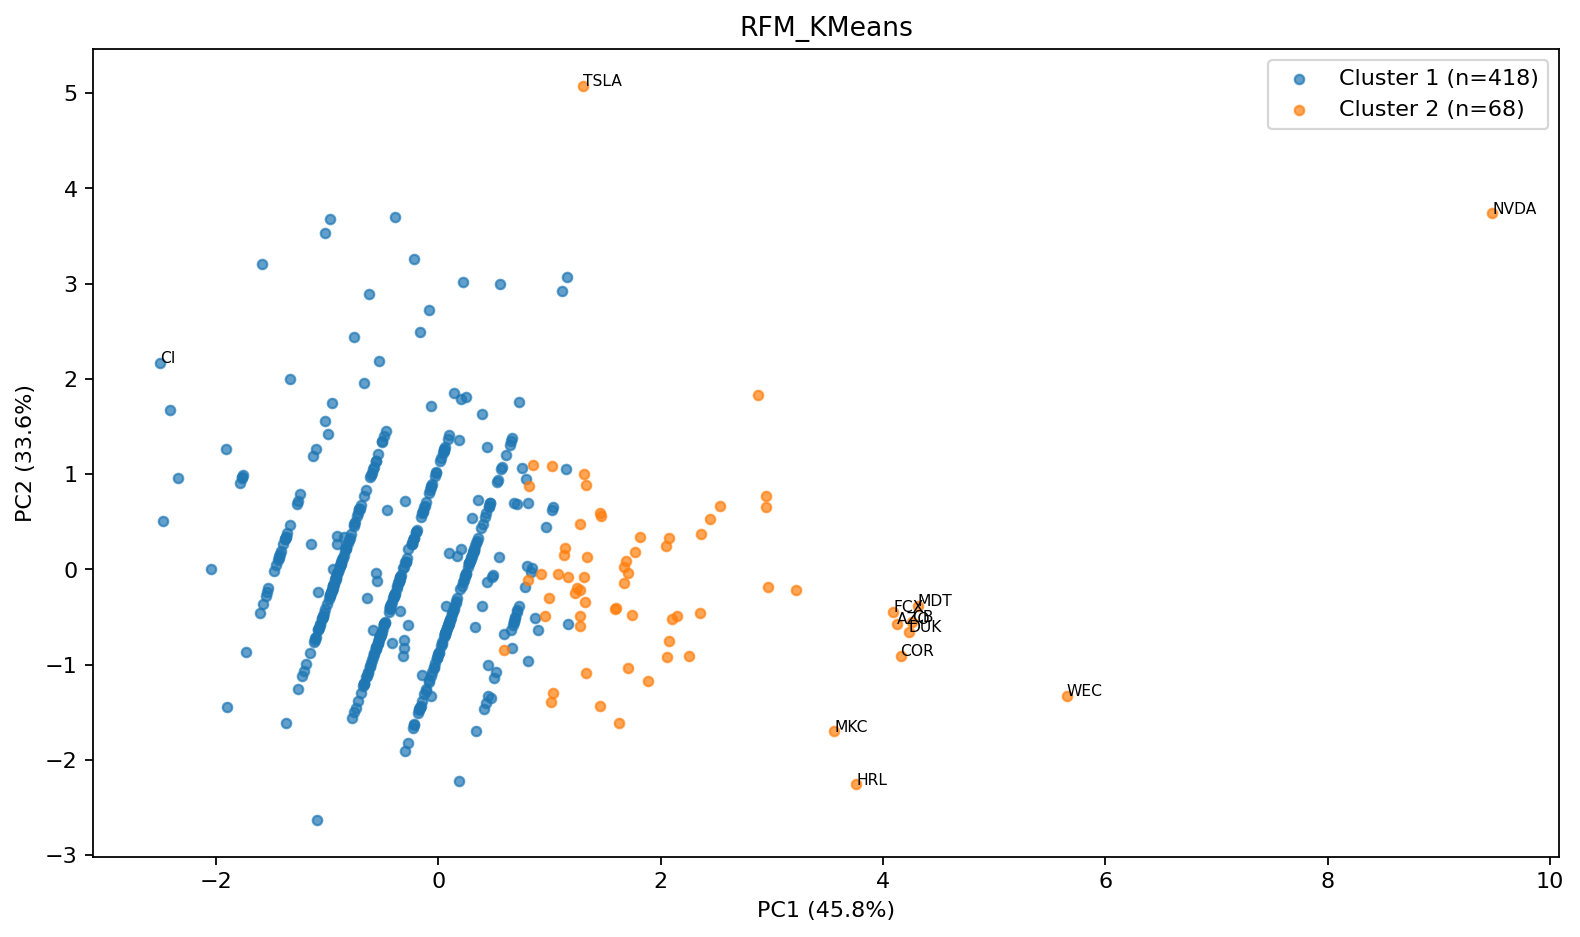

RFM_KMeans_sectors.png


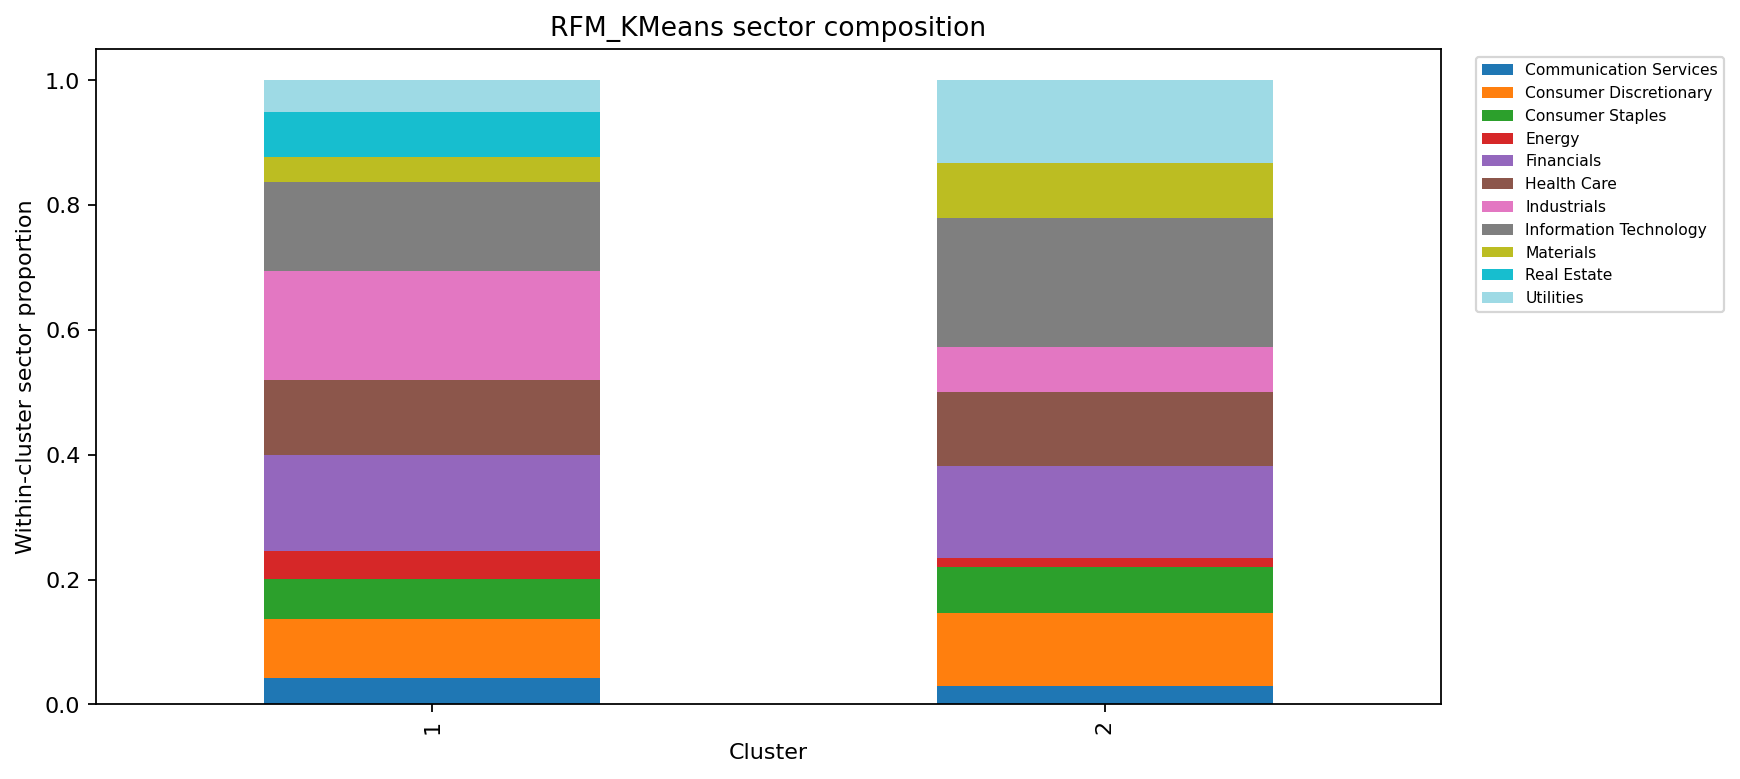

RFM_Ward_scatter.png


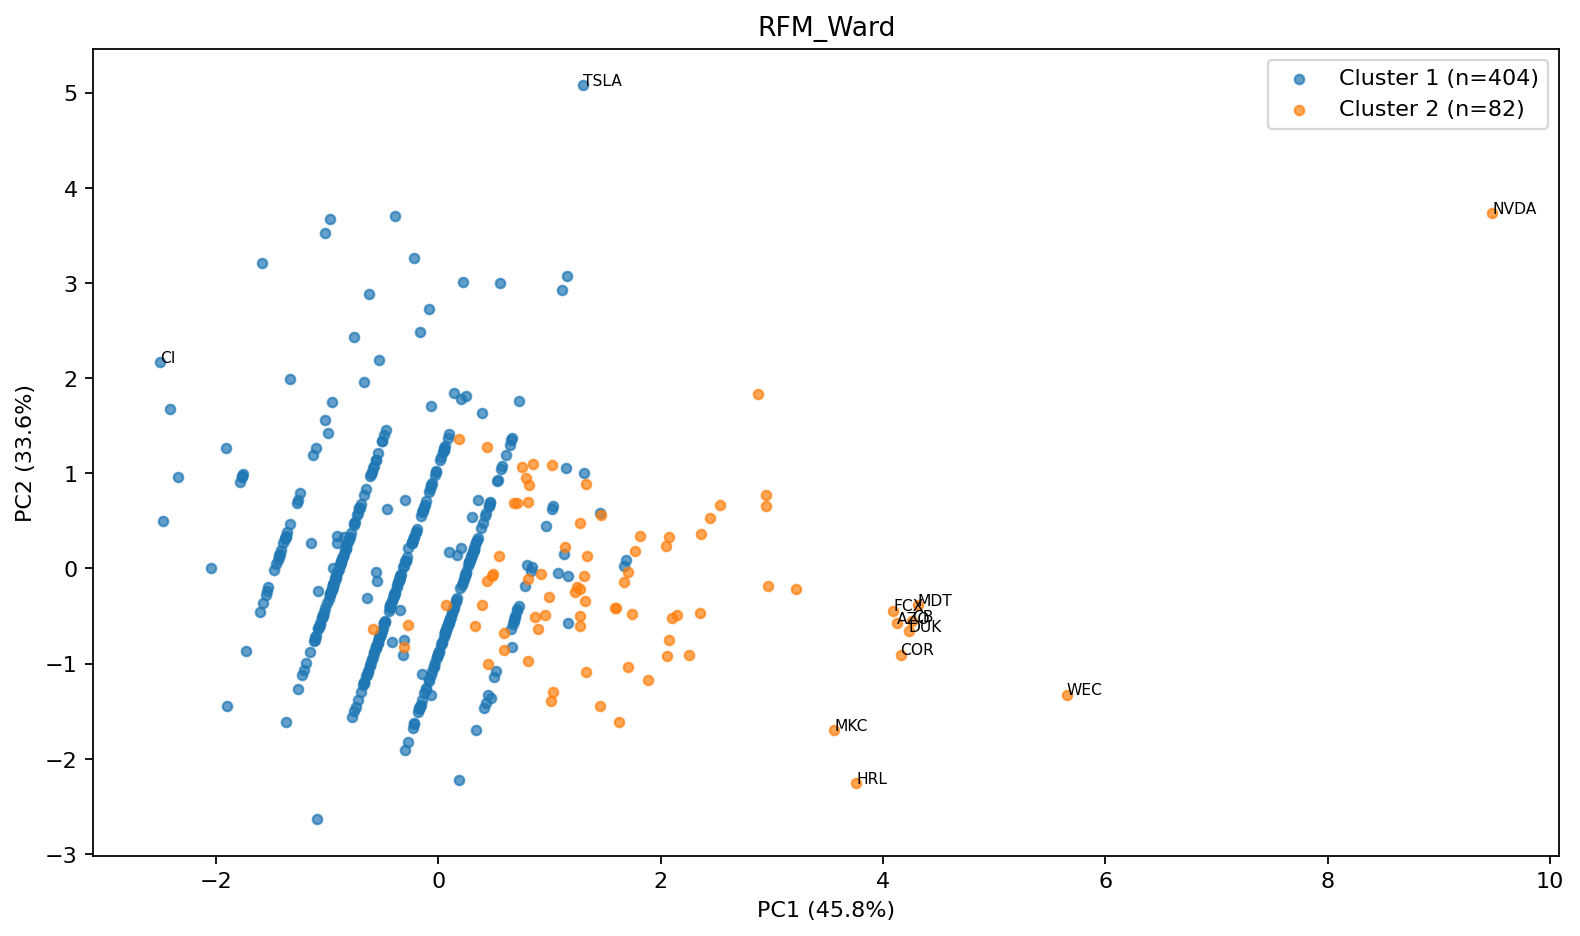

RFM_Ward_sectors.png


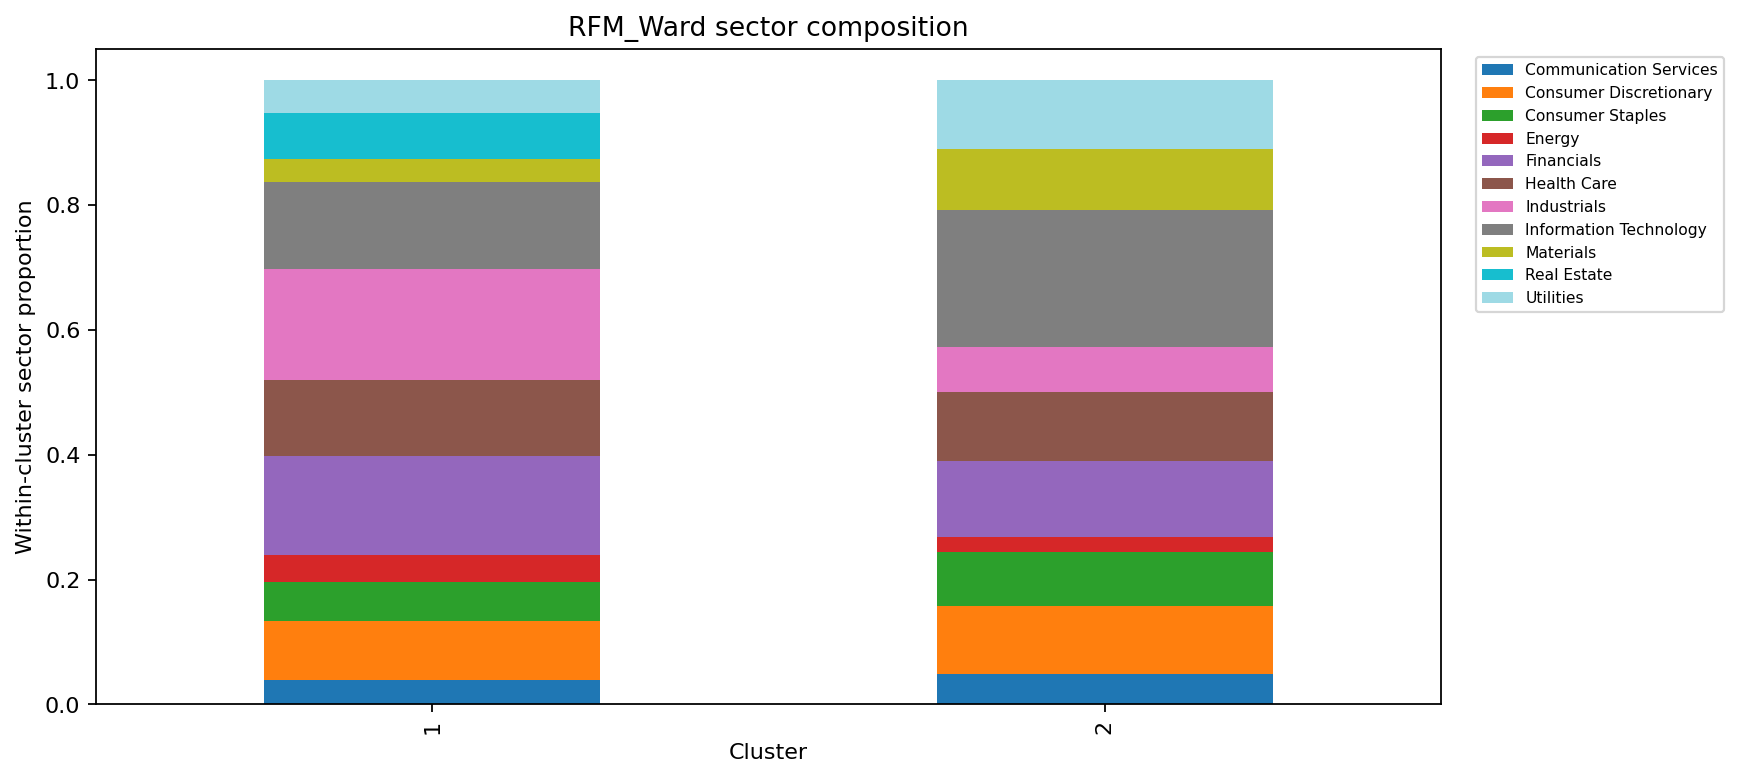

RFM_dendrogram.png


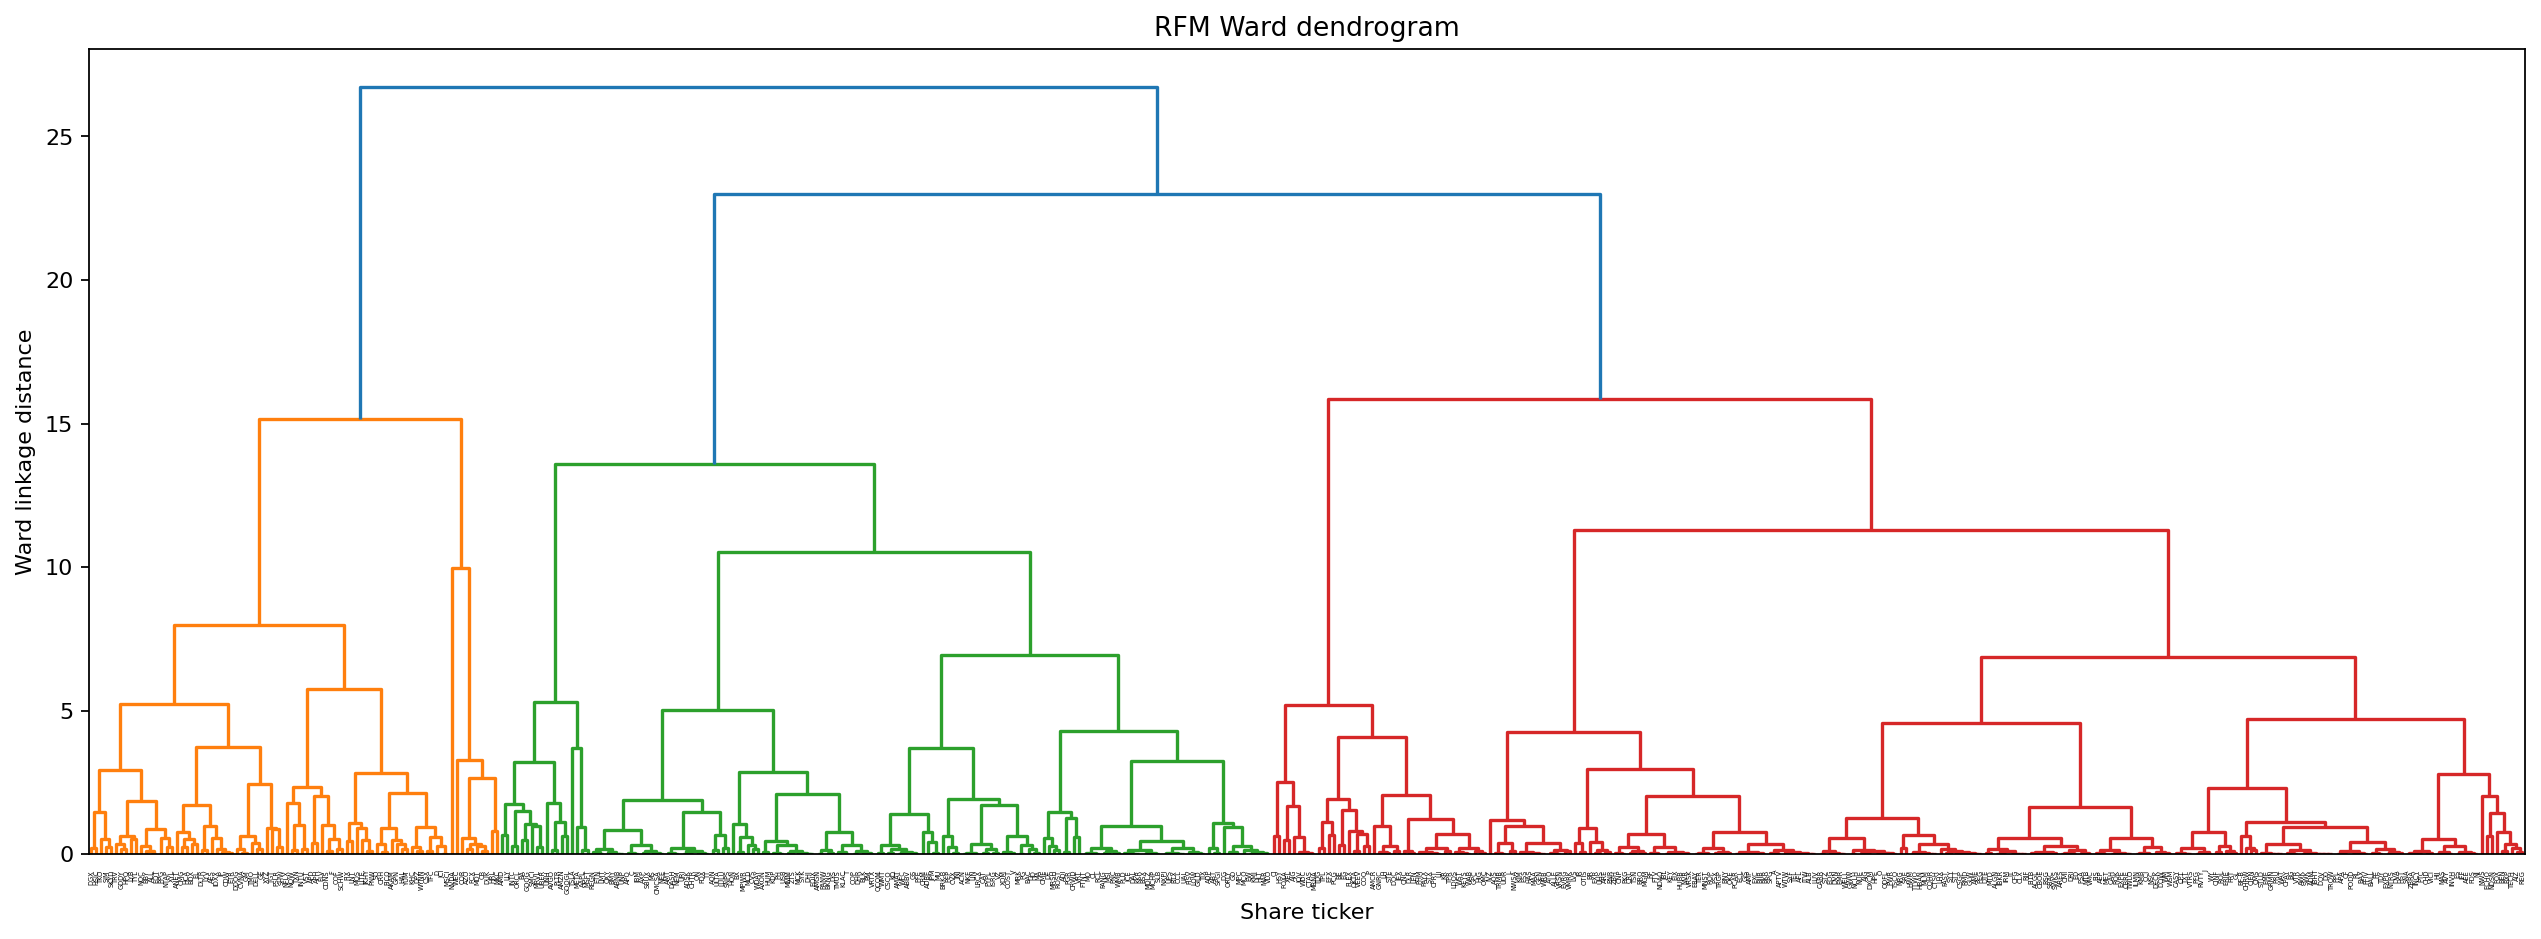

RFM_feature_distributions.png


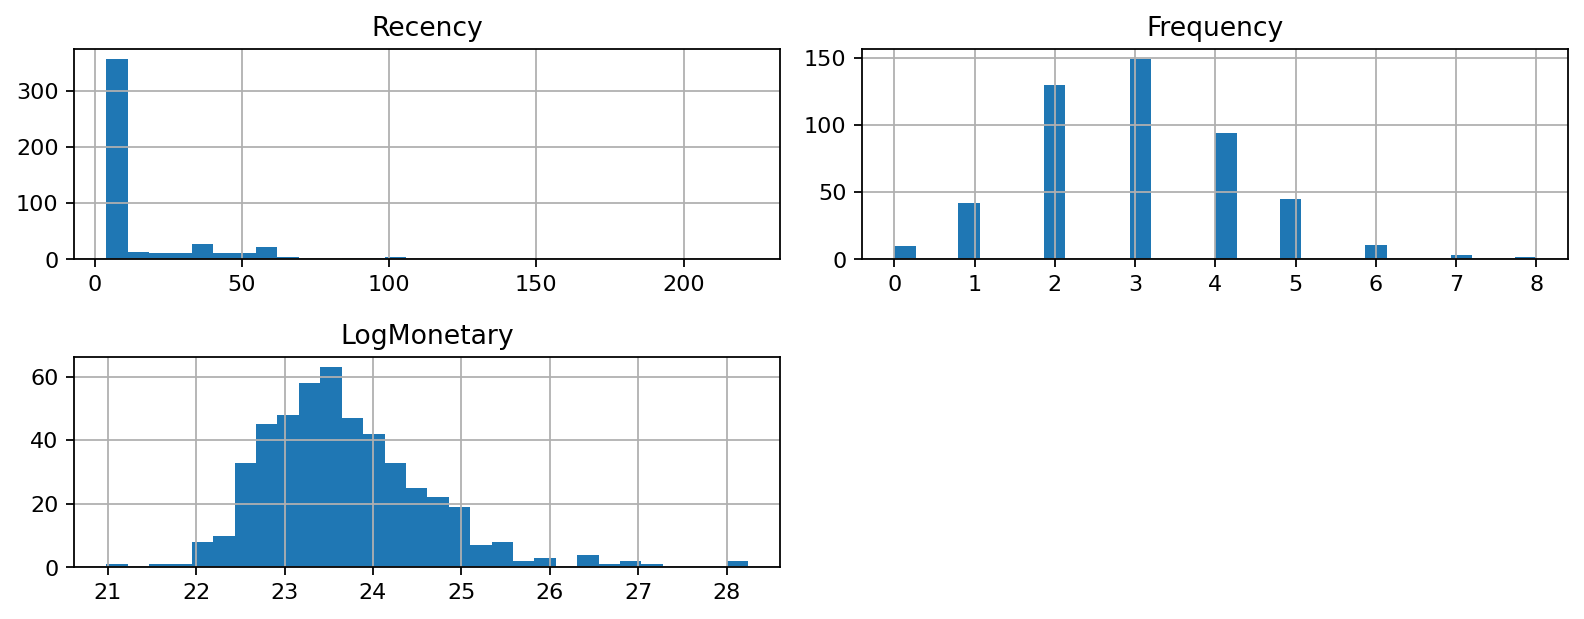

RiskReturn_KMeans_scatter.png


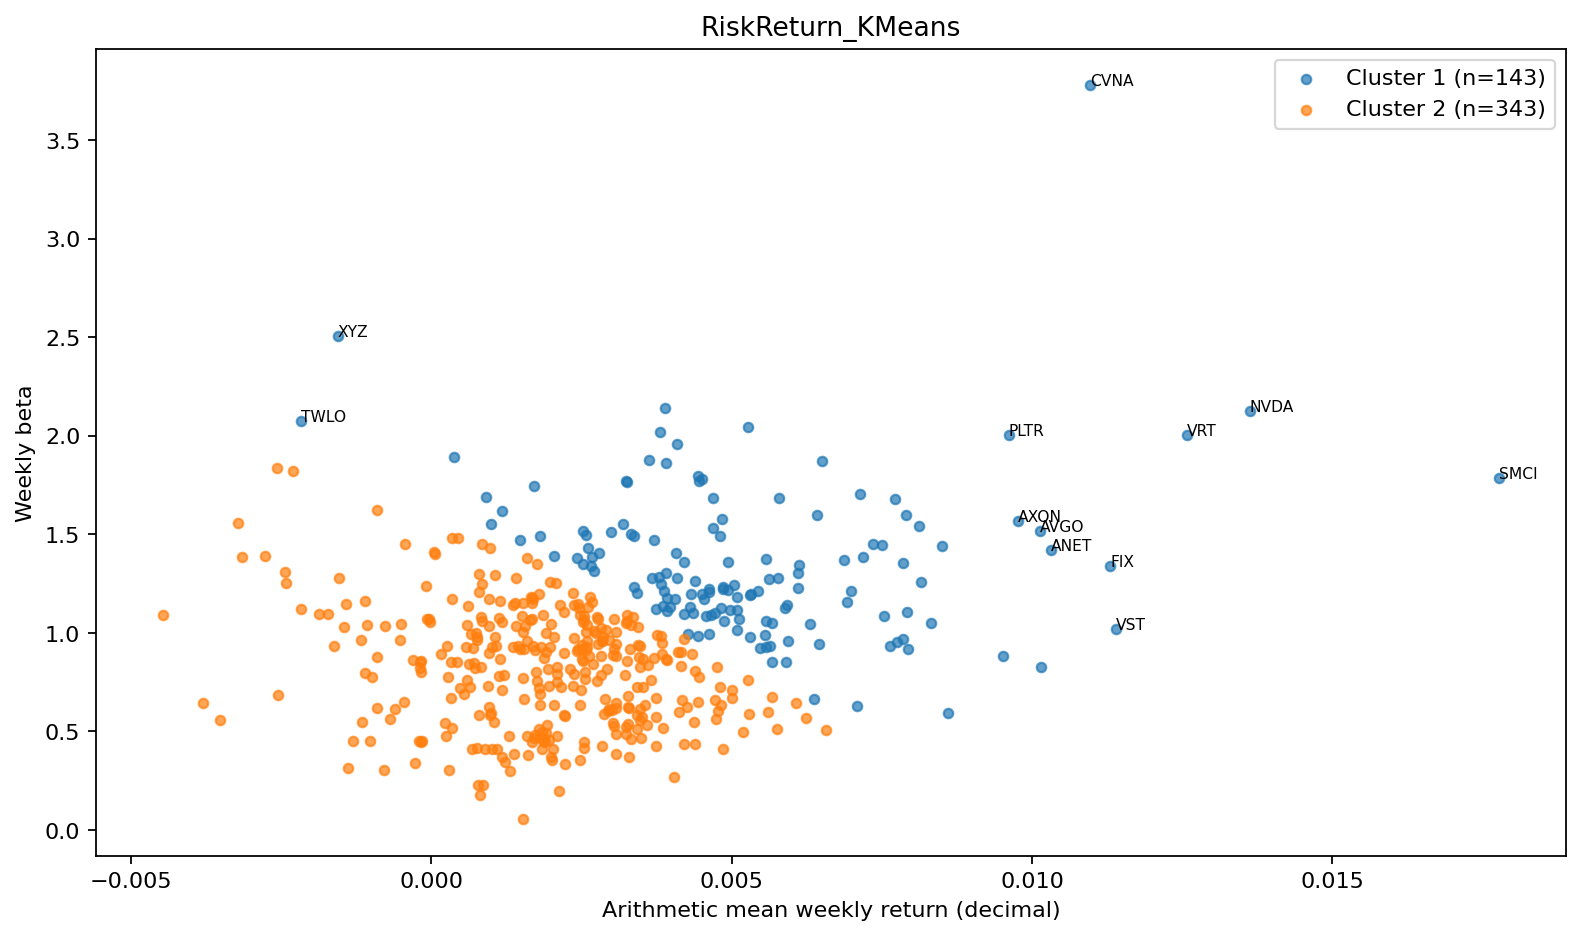

RiskReturn_KMeans_sectors.png


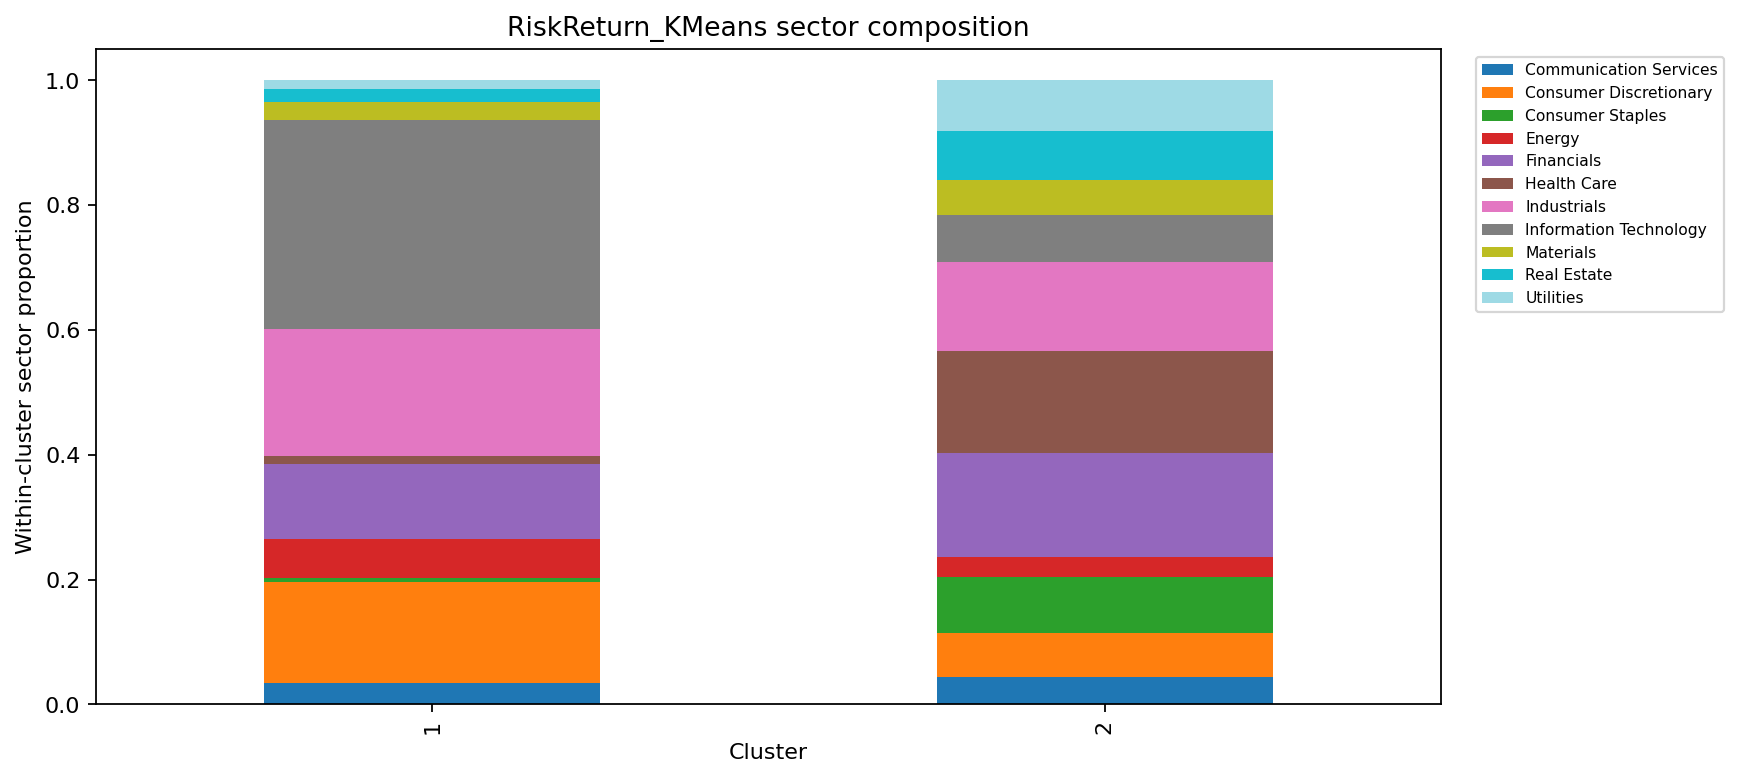

RiskReturn_Ward_scatter.png


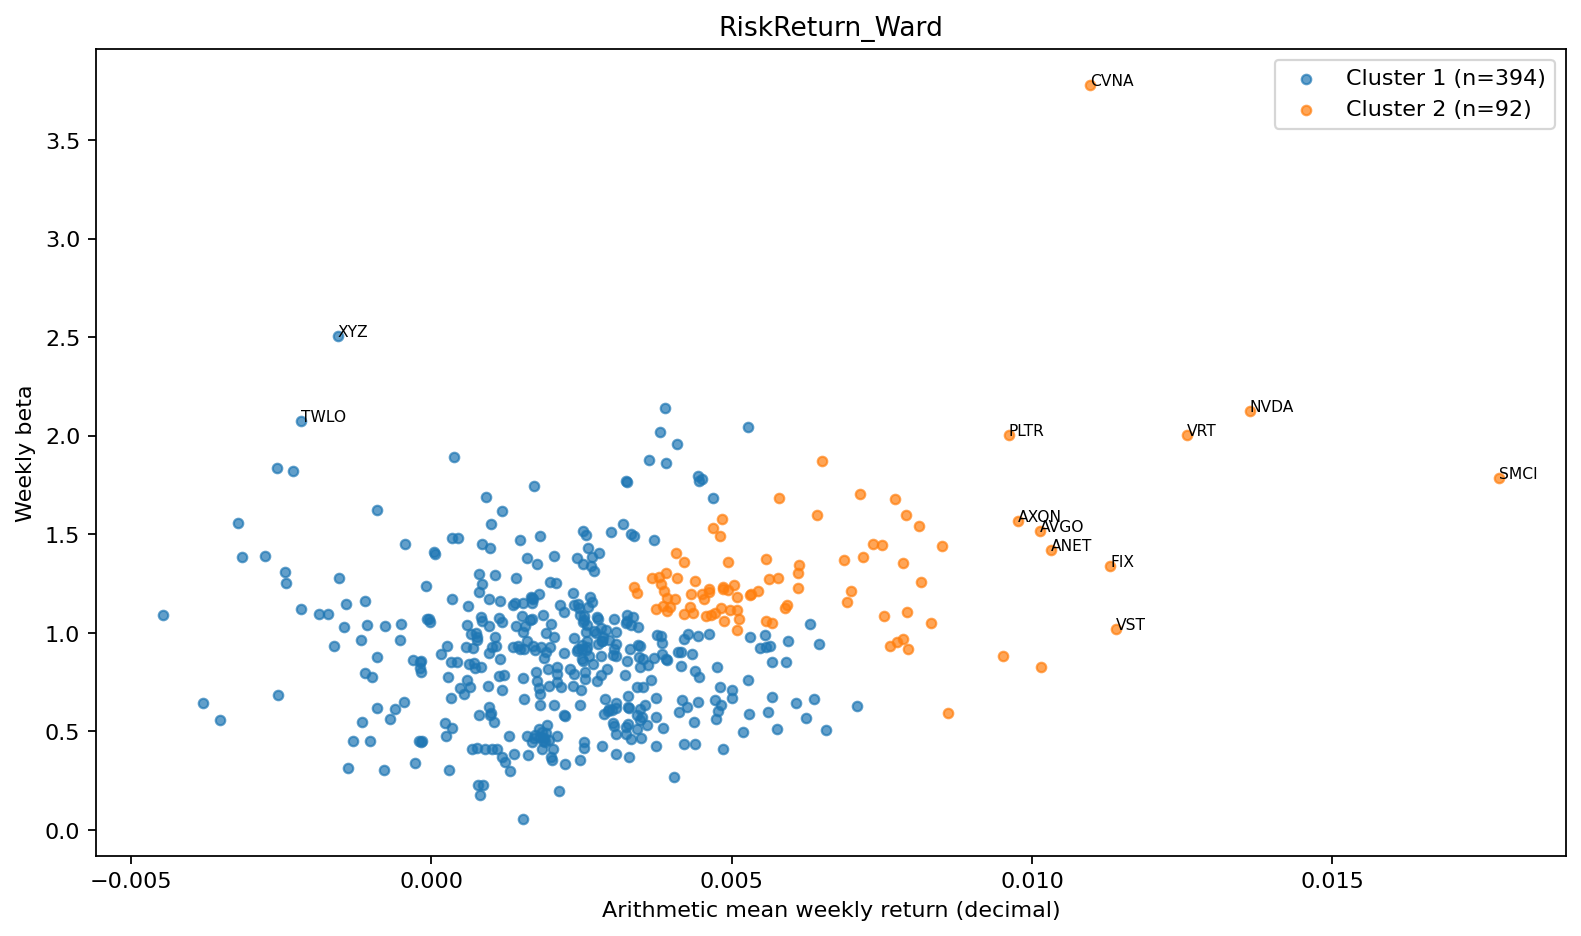

RiskReturn_Ward_sectors.png


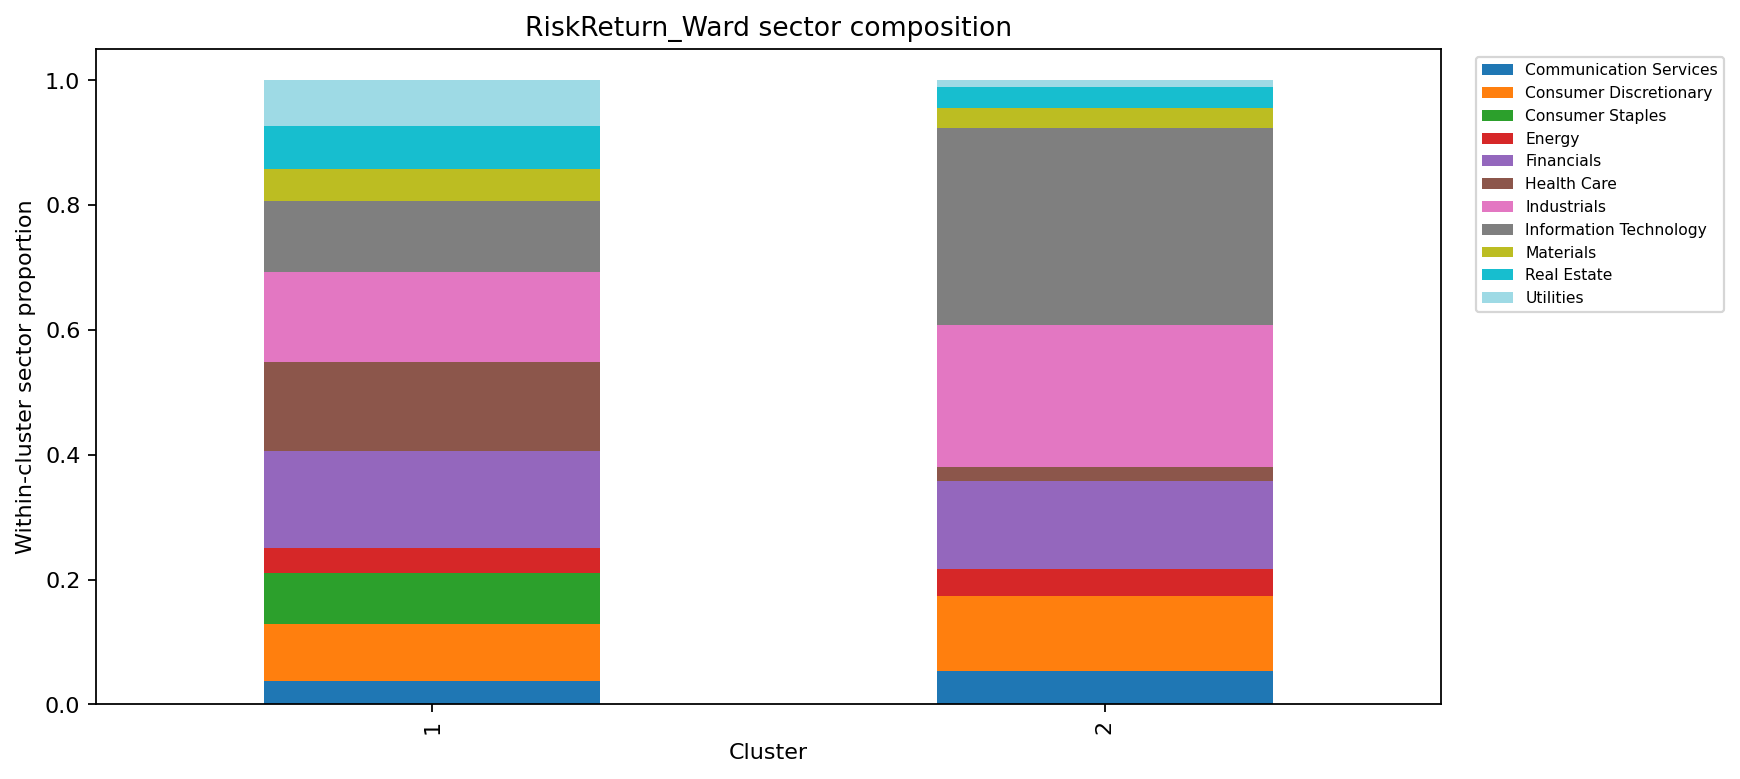

RiskReturn_dendrogram.png


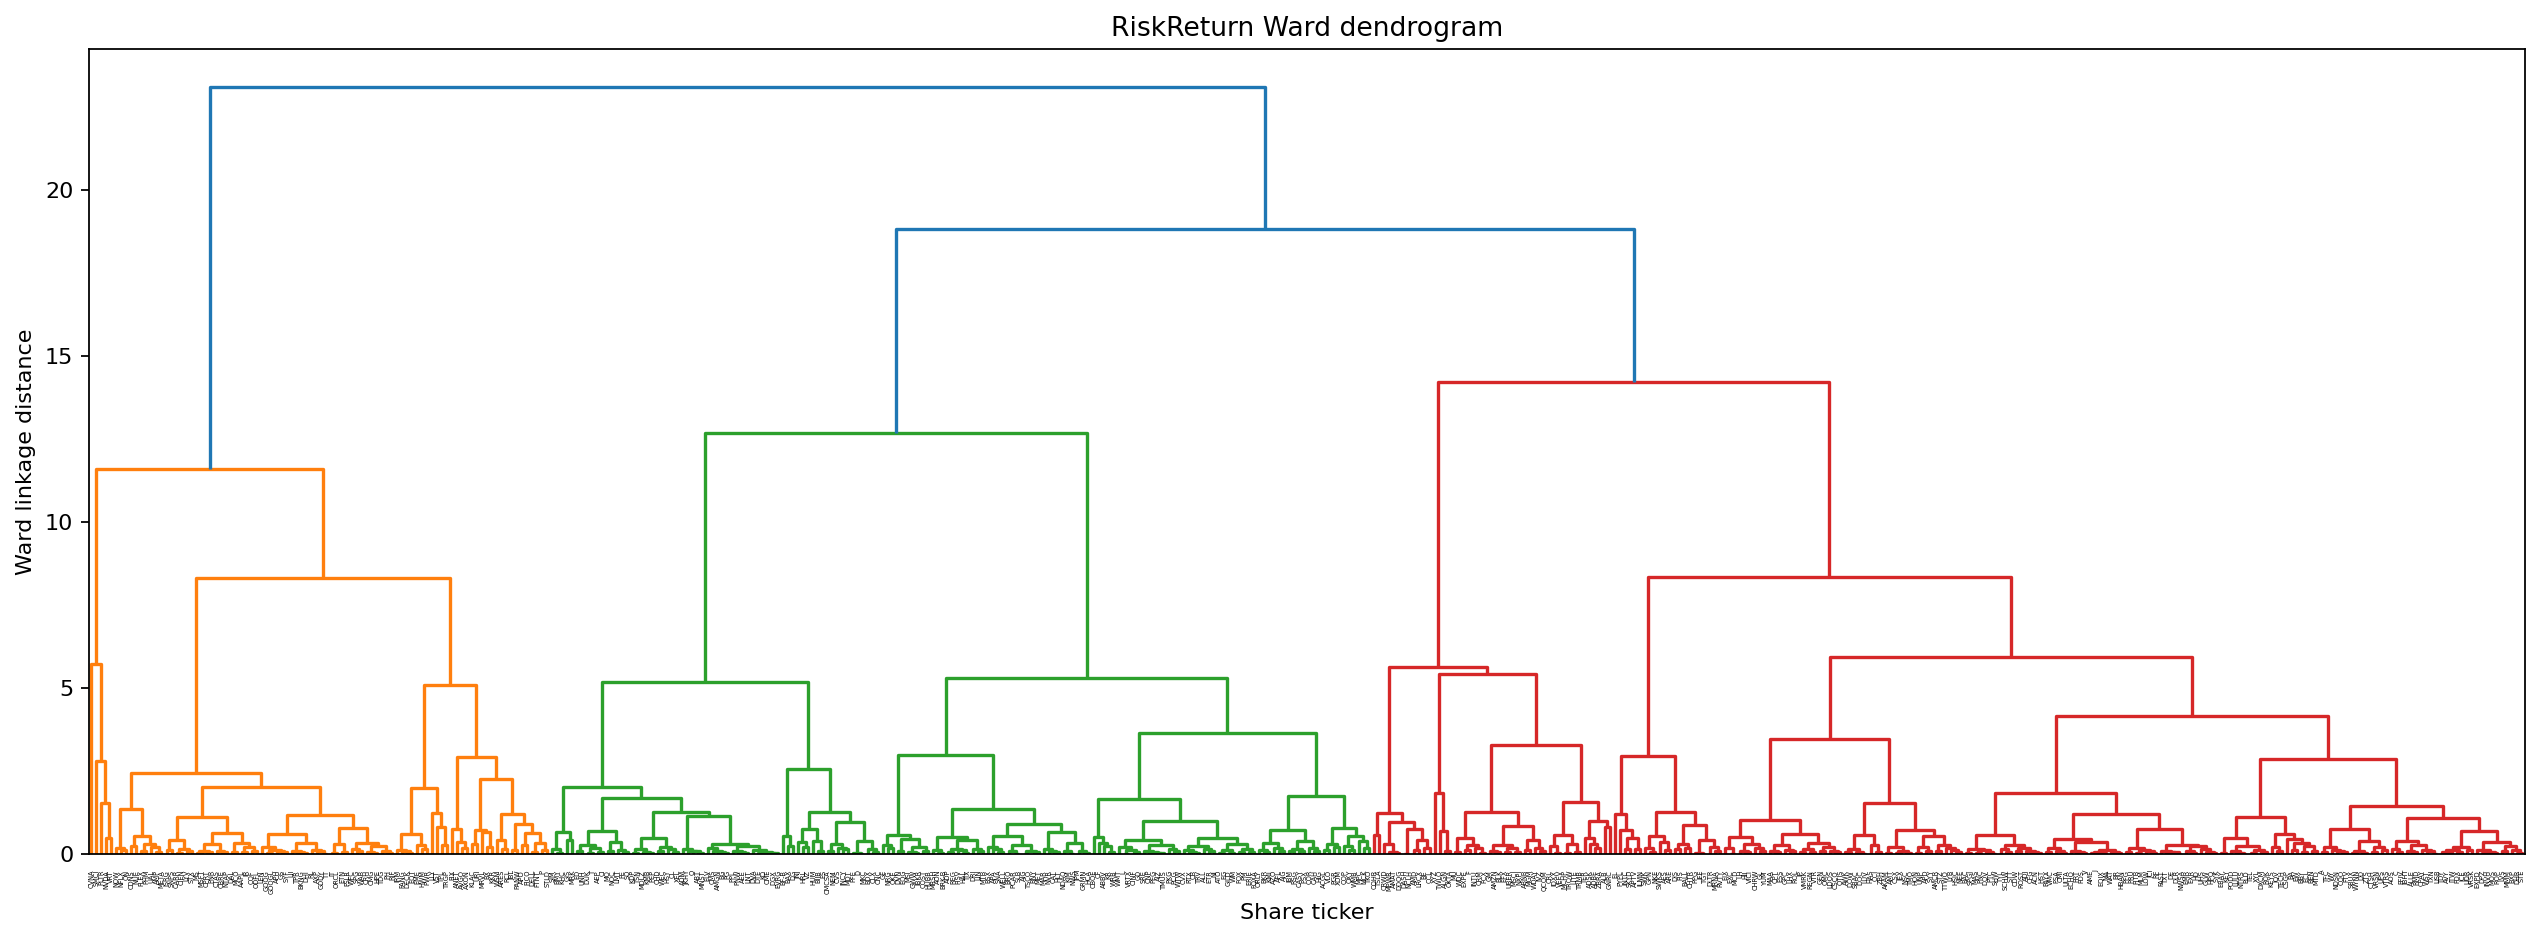

RiskReturn_feature_distributions.png


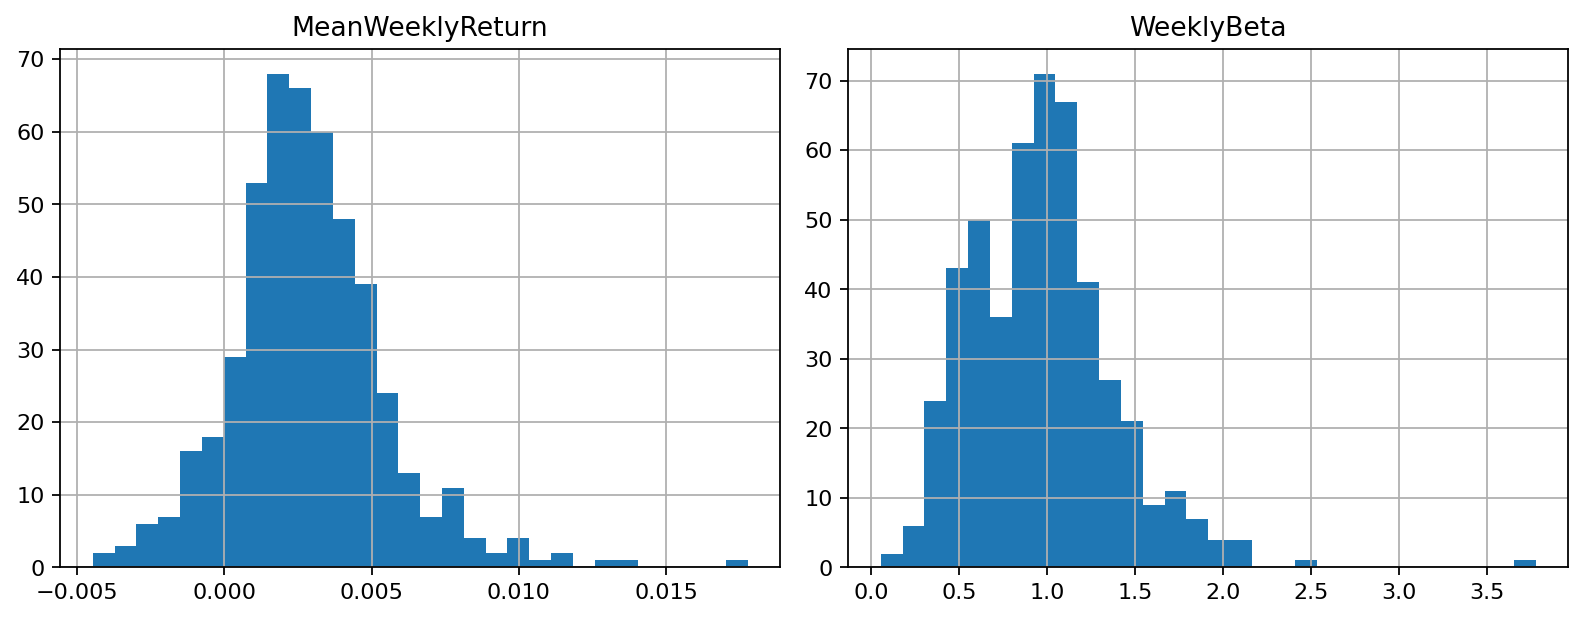

kmeans_inertia.png


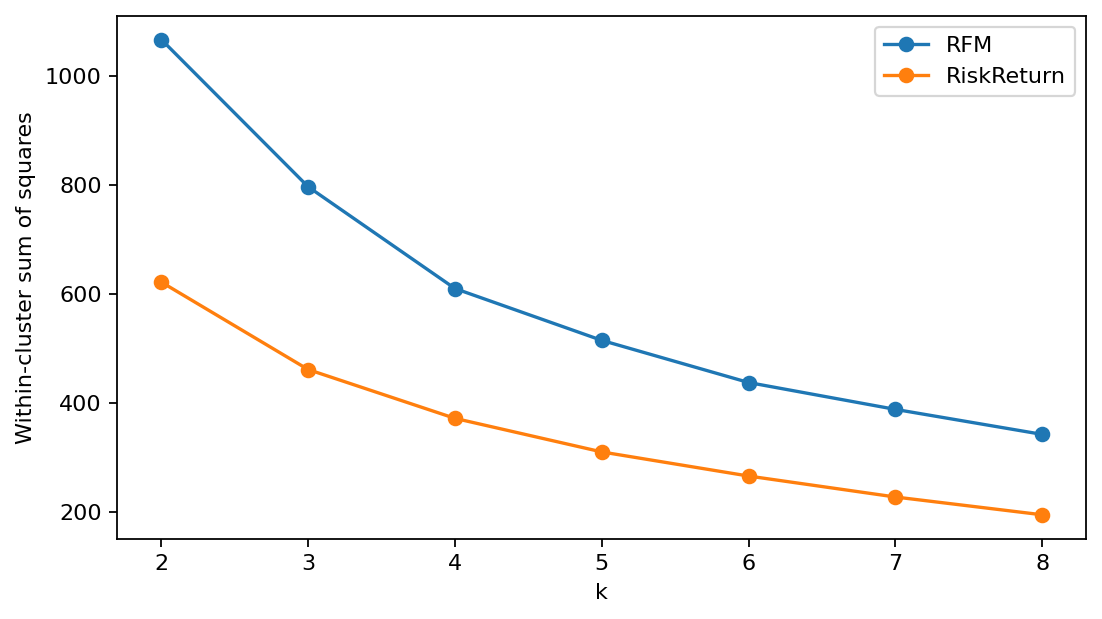

silhouette_comparison.png


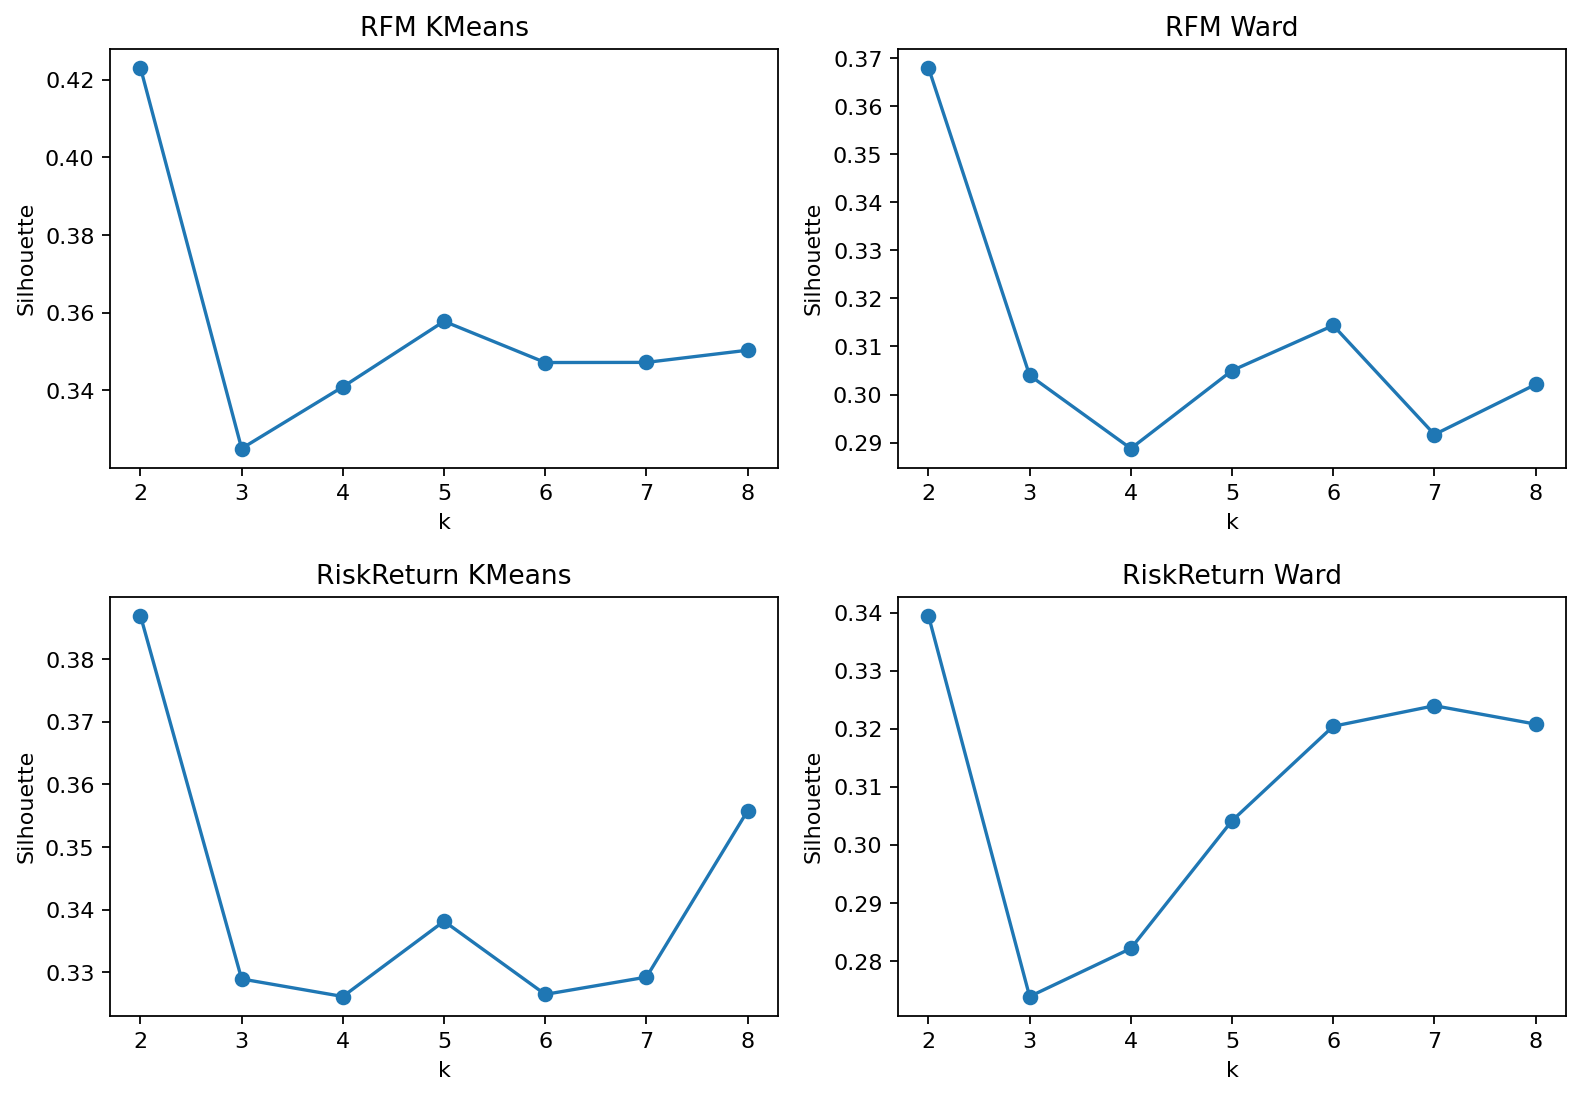

In [6]:
from IPython.display import Image, display
for path in sorted((ROOT / 'outputs').glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))

## Provenance and export

Record versions and checksums. The downloaded ZIP contains data and analysis outputs. Upload it here for checking and report completion. Colab storage is temporary.

In [7]:
versions = {p: importlib.metadata.version(p) for p in ['pandas','numpy','scipy','scikit-learn','matplotlib','yfinance']}
write_json(ROOT / 'outputs' / 'package_versions.json', versions)
write_json(ROOT / 'outputs' / 'file_checksums.json', {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in (ROOT / 'data').glob('*') if p.is_file()})
import shutil
archive = shutil.make_archive(str(ROOT.parent / 'Stock_Segmentation_Results'), 'zip', ROOT)
print(archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Open the archive from the local output folder.')

/content/Stock_Segmentation_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>